In [2]:
import sys, pathlib, importlib
import numpy as np
import torch
import matplotlib.pyplot as plt

# ---- EDIT THESE TWO LINES ONLY IF YOUR PATHS ARE DIFFERENT ----
FOLDER = pathlib.Path("/home/avash/Documents/research/transformer-pt-analysis-main/Experimental architecture")
CKPT = FOLDER / "Checkpoints" / "small_ffn.pth"
# ---------------------------------------------------------------

sys.path.insert(0, str(FOLDER))
import neural_net as nn_mod          # your file that defines MinimalTransformer and loads analysis.py
importlib.reload(nn_mod)             # picks up any edits you made to neural_net.py
device = nn_mod.device

ckpt = torch.load(CKPT, map_location=device, weights_only=False)   # your own file, so this is safe
state = ckpt["model_state_dict"] if "model_state_dict" in ckpt else ckpt
history = ckpt.get("history", {}) if "model_state_dict" in ckpt else {}

# ---------- 1. what is stored in the checkpoint ----------
print("Items stored in the checkpoint:", list(ckpt.keys()))
saved = False
for key in ("cfg", "config", "hparams", "hyperparameters", "args"):
    if key in ckpt:
        saved = True
        print(f"\nHyperparameters saved under '{key}':")
        val = ckpt[key]
        print(vars(val) if hasattr(val, "__dict__") else val)
if not saved:
    print("\nNo hyperparameters were saved in this file (only weights and training history).")
    print("They are worked out below from the shapes of the weights instead.")

# ---------- 2. work out the settings from the weight shapes ----------
hp = {}
if "token_embed.weight" in state:                      # transformer-style models
    hp["vocab_size"], hp["d_model"] = [int(v) for v in state["token_embed.weight"].shape]
    hp["p (modulus)"] = hp["vocab_size"] - 1
if "pos_embed.weight" in state:
    hp["max_seq_len"] = int(state["pos_embed.weight"].shape[0])
mlp_ids = {int(k.split(".")[1]) for k in state if k.startswith("mlp_layers.")}
attn_ids = {int(k.split(".")[1]) for k in state if k.startswith("attn_layers.")}
if mlp_ids:
    hp["num_layers"] = len(mlp_ids)
    hp["hidden_mlp (FFN width)"] = int(state["mlp_layers.0.net.0.weight"].shape[0])
    hp["FFN input width"] = int(state["mlp_layers.0.net.0.weight"].shape[1])
if attn_ids:
    hp["num_layers"] = len(attn_ids)
    hp["attention layers"] = len(attn_ids)
lin_ids = sorted({int(k.split(".")[1]) for k in state if k.startswith("net.") and k.endswith(".weight")})
if lin_ids and not mlp_ids:                            # plain ANN
    hp["num_layers"] = len(lin_ids) - 1
    hp["hidden_mlp (width)"] = int(state[f"net.{lin_ids[0]}.weight"].shape[0])
    hp["vocab_size"] = int(state[f"net.{lin_ids[-1]}.weight"].shape[0])
    hp["p (modulus)"] = hp["vocab_size"] - 1
hp["n_heads"] = "not stored in the weights (unused by the FFN-only model)"

print("\nSettings worked out from the weights:")
for k, v in hp.items():
    print(f"  {k:28s} {v}")

n_epochs = len(history.get("train_loss", []))
if n_epochs:
    print(f"\nTraining history: {n_epochs} epochs")
    print(f"  final train loss {history['train_loss'][-1]:.4g}  acc {history['train_acc'][-1]:.3f}")
    print(f"  final val   loss {history['val_loss'][-1]:.4g}  acc {history['val_acc'][-1]:.3f}")
    print(f"  spectral snapshots saved: {len(history.get('spectral', []))}")
else:
    print("\nNo training history was saved in this checkpoint (the curves will be left out).")

print("\nEvery weight tensor in the file:")
for k, v in state.items():
    print(f"  {k:36s} {tuple(v.shape)}")

# ---------- 3. rebuild the model and load the weights ----------
p = hp["p (modulus)"]
model = nn_mod.MinimalTransformer(
    vocab_size=hp["vocab_size"],
    d_model=hp.get("d_model", 128),
    n_heads=4,                                          # not stored; unused by the FFN-only model
    num_layers=hp.get("num_layers", 1),
    max_seq_len=hp.get("max_seq_len", 3),
    hidden_mlp=hp.get("hidden_mlp (FFN width)", hp.get("hidden_mlp (width)", 512)),
).to(device)
model.load_state_dict(state)
model.eval()
n_params = sum(q.numel() for q in model.parameters())
print(f"\nModel loaded. Total parameters: {n_params:,}")

analysis loaded from: /home/avash/Documents/research/transformer-pt-analysis-main/src/analysis.py
analysis loaded from: /home/avash/Documents/research/transformer-pt-analysis-main/src/analysis.py
Items stored in the checkpoint: ['model_state_dict', 'history']

No hyperparameters were saved in this file (only weights and training history).
They are worked out below from the shapes of the weights instead.

Settings worked out from the weights:
  vocab_size                   150
  d_model                      32
  p (modulus)                  149
  max_seq_len                  3
  num_layers                   1
  hidden_mlp (FFN width)       32
  FFN input width              96
  n_heads                      not stored in the weights (unused by the FFN-only model)

Training history: 13500 epochs
  final train loss 1.095e-06  acc 1.000
  final val   loss 3.488e-06  acc 1.000
  spectral snapshots saved: 270

Every weight tensor in the file:
  token_embed.weight                   (150, 32)
 

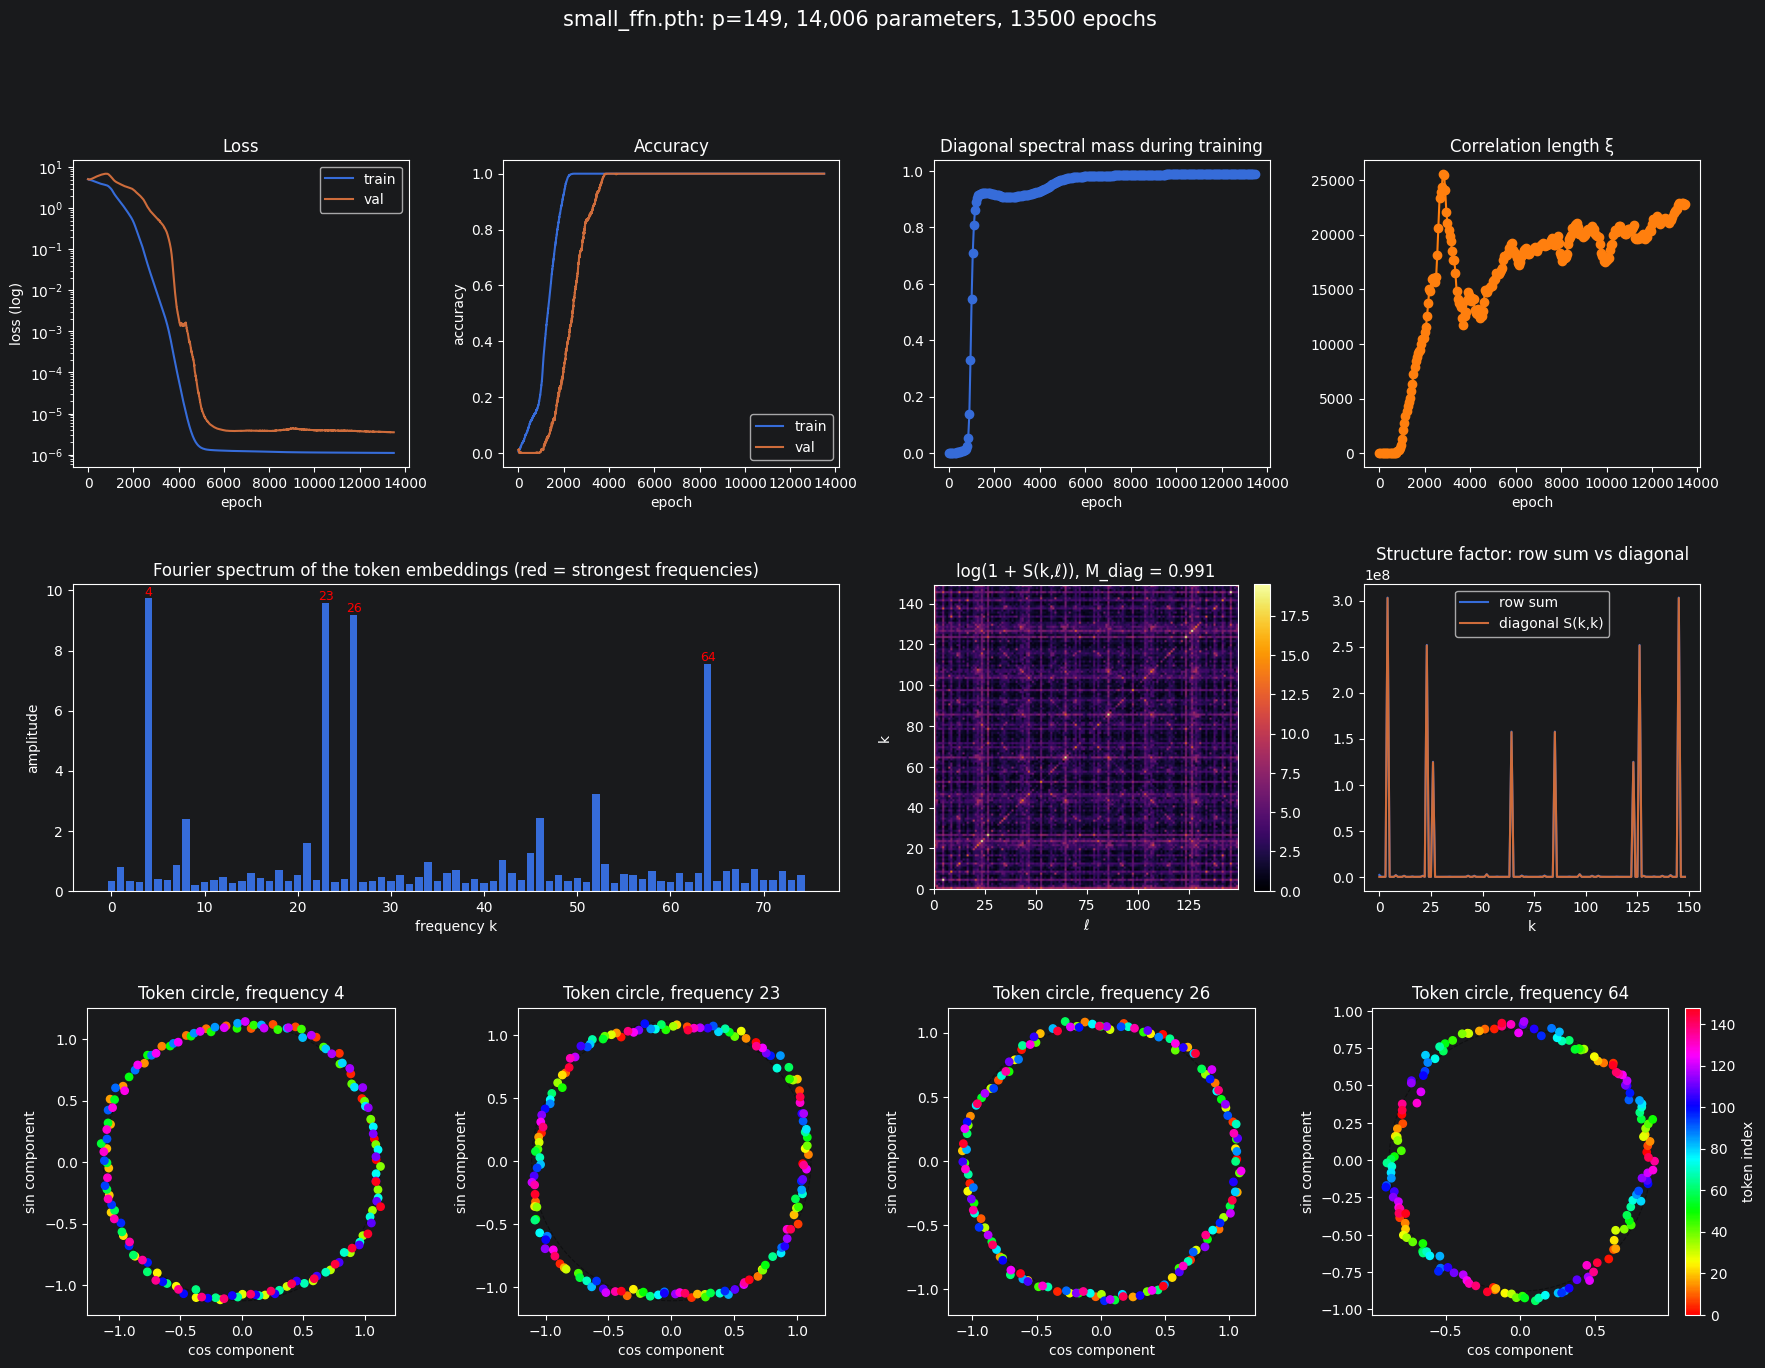

In [3]:
def draw_dashboard(history, W_E, S, m_diag, p, title="", top_k=4):
    """One figure: loss, accuracy, spectral history, Fourier spectrum, structure factor, trig circles."""
    amp = np.sqrt((np.abs(np.fft.rfft(W_E, axis=0, norm="ortho")) ** 2).sum(-1))
    freqs = np.argsort(amp[1:])[::-1][:top_k] + 1          # strongest frequencies, DC skipped
    k = np.arange(p)

    fig = plt.figure(figsize=(21, 15))
    gs = fig.add_gridspec(3, 4, hspace=0.38, wspace=0.28)
    fig.suptitle(title, fontsize=15)

    # --- row 1: training history ---
    ax = fig.add_subplot(gs[0, 0])
    if history.get("train_loss"):
        ep = np.arange(1, len(history["train_loss"]) + 1)
        ax.semilogy(ep, history["train_loss"], label="train")
        ax.semilogy(ep, history["val_loss"], label="val")
        ax.legend()
    ax.set_title("Loss"); ax.set_xlabel("epoch"); ax.set_ylabel("loss (log)")

    ax = fig.add_subplot(gs[0, 1])
    if history.get("train_acc"):
        ax.plot(ep, history["train_acc"], label="train")
        ax.plot(ep, history["val_acc"], label="val")
        ax.legend()
    ax.set_title("Accuracy"); ax.set_xlabel("epoch"); ax.set_ylabel("accuracy")

    snaps = history.get("spectral", [])
    ax = fig.add_subplot(gs[0, 2])
    if snaps:
        ax.plot([s["epoch"] for s in snaps], [s["diag_mass"] for s in snaps], "o-")
    else:
        ax.text(0.5, 0.5, "no spectral history saved", ha="center", transform=ax.transAxes)
    ax.set_title("Diagonal spectral mass during training"); ax.set_xlabel("epoch")

    ax = fig.add_subplot(gs[0, 3])
    if snaps:
        ax.plot([s["epoch"] for s in snaps], [s["xi"] for s in snaps], "o-", color="tab:orange")
    else:
        ax.text(0.5, 0.5, "no spectral history saved", ha="center", transform=ax.transAxes)
    ax.set_title("Correlation length ξ"); ax.set_xlabel("epoch")

    # --- row 2: frequency content ---
    ax = fig.add_subplot(gs[1, 0:2])
    ax.bar(np.arange(len(amp)), amp)
    for f in freqs:
        ax.annotate(str(f), (f, amp[f]), ha="center", va="bottom", color="red", fontsize=9)
    ax.set_title("Fourier spectrum of the token embeddings (red = strongest frequencies)")
    ax.set_xlabel("frequency k"); ax.set_ylabel("amplitude")

    n = S.shape[0]
    S_show = S.copy(); S_show[0, 0] = 0.0
    ax = fig.add_subplot(gs[1, 2])
    im = ax.imshow(np.log1p(S_show), origin="lower", cmap="inferno", extent=[0, n, 0, n])
    ax.set_title(f"log(1 + S(k,ℓ)), M_diag = {m_diag:.3f}")
    ax.set_xlabel("ℓ"); ax.set_ylabel("k"); fig.colorbar(im, ax=ax, fraction=0.046)

    ax = fig.add_subplot(gs[1, 3])
    idx = np.arange(n)
    ax.plot(idx, S_show.sum(axis=1), label="row sum")
    ax.plot(idx, S_show[idx, idx], label="diagonal S(k,k)")
    ax.set_title("Structure factor: row sum vs diagonal"); ax.set_xlabel("k"); ax.legend()

    # --- row 3: the circles (tokens on a circle = trig solution) ---
    for j, f in enumerate(freqs):
        ax = fig.add_subplot(gs[2, j])
        cos_v = np.cos(2 * np.pi * f * k / p); cos_v /= np.linalg.norm(cos_v)
        sin_v = np.sin(2 * np.pi * f * k / p); sin_v /= np.linalg.norm(sin_v)
        u = cos_v @ W_E; u /= np.linalg.norm(u)
        v = sin_v @ W_E; v /= np.linalg.norm(v)
        cx, cy = W_E @ u, W_E @ v
        r = np.hypot(cx, cy).mean()
        sc = ax.scatter(cx, cy, c=k, cmap="hsv", s=28, zorder=3)
        th = np.linspace(0, 2 * np.pi, 300)
        ax.plot(r * np.cos(th), r * np.sin(th), "k--", lw=0.8, alpha=0.4)
        ax.set_aspect("equal")
        ax.set_title(f"Token circle, frequency {f}")
        ax.set_xlabel("cos component"); ax.set_ylabel("sin component")
        if j == len(freqs) - 1:
            fig.colorbar(sc, ax=ax, fraction=0.046, label="token index")
    plt.show()


# ---- get the model's numbers and draw everything ----
obs = nn_mod.a.monitor_spectral_observables(
    model=model, n=p, seq_len=hp.get("max_seq_len", 3),
    device=device, batch_size=1024, eq_token=p,
)
S = obs["structure_factor"].cpu().numpy()
W_E = model.token_embeddings().cpu().numpy()[:p]
epochs_txt = f", {n_epochs} epochs" if n_epochs else ""
draw_dashboard(
    history, W_E, S, obs["diagonal_spectral_mass"], p,
    title=f"{CKPT.name}: p={p}, {n_params:,} parameters{epochs_txt}",
)